In [1]:
import pandas as pd
import numpy as np
import yfinance as yf
import matplotlib.pyplot as plt
from itertools import product
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.metrics import mean_squared_error, r2_score

In [2]:
# Same stock and dates as ARIMA.ipynb. Make adjusted-price behavior explicit.
stk_data = yf.download("TATACONSUM.NS", start="2021-06-01", end="2022-01-05", auto_adjust=True)

[*********************100%***********************]  1 of 1 completed


In [4]:
if stk_data.empty:
    raise ValueError("No prices downloaded. Check the ticker, dates, and internet connection.")

In [5]:
# Flatten single-ticker column names and keep OHLC prices in date order.
if stk_data.columns.nlevels > 1:
    stk_data.columns = stk_data.columns.get_level_values(0)

In [6]:
stk_data = stk_data[["Open", "High", "Low", "Close"]].sort_index()
stk_data = stk_data.loc[~stk_data.index.duplicated(keep="last")].dropna()
column = "Close"
stk_data.head()

Price,Open,High,Low,Close
Date,,,,
2021-06-01,635.153992,636.537262,626.568251,635.153992
2021-06-02,634.867725,643.691957,629.764003,642.547180
2021-06-03,644.884494,651.562292,642.261073,648.700378
2021-06-04,649.511186,658.192358,643.930478,655.330444
2021-06-07,658.240032,674.457540,655.664298,667.732056


In [7]:
# Same target as the original notebook: first differences of Close.
close = stk_data[column].diff().dropna()
data1 = close.copy()

In [8]:
training_size = int(len(data1) * 0.80)
train = data1.iloc[:training_size]
test = data1.iloc[training_size:]
seasonal_period = 5
if len(train) < 6 * seasonal_period or len(test) < 2:
    raise ValueError("Use a longer date range for seasonal fitting and test evaluation.")
print("Training observations:", len(train))
print("Test observations:", len(test))

Training observations: 119
Test observations: 30


In [9]:
# Diagnose stationarity using training data only.
result = adfuller(train)
print("ADF Statistic:", result[0])
print("p-value:", result[1])
print("Reject unit root at 5%:", result[1] < 0.05)

ADF Statistic: -10.925465699196238
p-value: 1.0128495070896382e-19
Reject unit root at 5%: True


/var/folders/tk/w8w2mxns4s16myv7xnc6y6z40000gp/T/ipykernel_3823/2360732959.py:2: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(train)


In [10]:
# Initial SARIMA model: no further ordinary or seasonal differences.
order = (1, 0, 1)
seasonal_order = (1, 0, 1, seasonal_period)
model = SARIMAX(train.to_numpy(), order=order, seasonal_order=seasonal_order, trend="n")
model_fit = model.fit(disp=False, maxiter=200)
print(model_fit.summary())
print("Converged:", model_fit.mle_retvals.get("converged", False))

                                     SARIMAX Results                                     
Dep. Variable:                                 y   No. Observations:                  119
Model:             SARIMAX(1, 0, 1)x(1, 0, 1, 5)   Log Likelihood                -436.996
Date:                           Thu, 29 Oct 2026   AIC                            883.993
Time:                                   15:12:35   BIC                            897.888
Sample:                                        0   HQIC                           889.635
                                           - 119                                         
Covariance Type:                             opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.8974      0.339      2.647      0.008       0.233       1.562
ma.L1         -0.8612      0.384     -2.245

/opt/anaconda3/envs/TSA/lib/python3.11/site-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
/opt/anaconda3/envs/TSA/lib/python3.11/site-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params


In [11]:
forecast_values = model_fit.forecast(steps=len(test))
predictions = pd.Series(np.asarray(forecast_values), index=test.index, name="Forecast")
print(predictions.head())
mse = mean_squared_error(test, predictions)
rmse = np.sqrt(mse)
r2 = r2_score(test, predictions)
print("Initial test MSE:", mse)
print("Initial test RMSE:", rmse)
print("Initial test R2 score:", r2)

Date
2021-11-24   -1.709673
2021-11-25   -0.588933
2021-11-26   -1.294398
2021-11-29   -3.155242
2021-11-30    0.391467
Name: Forecast, dtype: float64
Initial test MSE: 159.1035729696875
Initial test RMSE: 12.613626479711831
Initial test R2 score: -0.02531740444082331


In [12]:
results = []
best_fit = None
best_aic = np.inf
best_order = None
best_seasonal_order = None
for p, q, P, Q in product(range(3), range(3), range(2), range(2)):
    candidate_order = (p, 0, q)
    candidate_seasonal = (P, 0, Q, seasonal_period)
    try:
        candidate = SARIMAX(train.to_numpy(), order=candidate_order,
                            seasonal_order=candidate_seasonal, trend="n").fit(disp=False, maxiter=200)
        converged = bool(candidate.mle_retvals.get("converged", False))
        results.append({"order": candidate_order, "seasonal_order": candidate_seasonal,
                        "AIC": candidate.aic, "converged": converged, "error": None})
        if converged and np.isfinite(candidate.aic) and candidate.aic < best_aic:
            best_aic = candidate.aic
            best_fit = candidate
            best_order = candidate_order
            best_seasonal_order = candidate_seasonal
    except Exception as error:
        results.append({"order": candidate_order, "seasonal_order": candidate_seasonal,
                        "AIC": np.nan, "converged": False, "error": str(error)})
comparison = pd.DataFrame(results).sort_values("AIC", na_position="last")
print(comparison.to_string(index=False))
if best_fit is None:
    raise RuntimeError("No candidate converged. Review diagnostics or extend the training period.")
print("Selected order:", best_order)
print("Selected seasonal order:", best_seasonal_order)


/opt/anaconda3/envs/TSA/lib/python3.11/site-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
/opt/anaconda3/envs/TSA/lib/python3.11/site-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params
/opt/anaconda3/envs/TSA/lib/python3.11/site-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
/opt/anaconda3/envs/TSA/lib/python3.11/site-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params
/opt/anaconda3/envs/TSA/lib/python3.11/site-pack

    order seasonal_order        AIC  converged error
(2, 0, 2)   (0, 0, 1, 5) 878.272256       True  None
(2, 0, 2)   (1, 0, 0, 5) 878.391511       True  None
(0, 0, 0)   (0, 0, 0, 5) 878.811920       True  None
(0, 0, 0)   (0, 0, 1, 5) 879.162376       True  None
(0, 0, 0)   (1, 0, 0, 5) 879.263475       True  None
(2, 0, 2)   (1, 0, 1, 5) 880.170758       True  None
(0, 0, 0)   (1, 0, 1, 5) 880.667163       True  None
(1, 0, 0)   (0, 0, 0, 5) 880.811519       True  None
(0, 0, 1)   (0, 0, 0, 5) 880.811561       True  None
(1, 0, 0)   (0, 0, 1, 5) 881.126401       True  None
(0, 0, 1)   (0, 0, 1, 5) 881.129991       True  None
(1, 0, 0)   (1, 0, 0, 5) 881.232460       True  None
(0, 0, 1)   (1, 0, 0, 5) 881.235421       True  None
(0, 0, 2)   (0, 0, 0, 5) 882.311440       True  None
(2, 0, 0)   (0, 0, 0, 5) 882.327330       True  None
(1, 0, 0)   (1, 0, 1, 5) 882.607343       True  None
(0, 0, 1)   (1, 0, 1, 5) 882.614272       True  None
(1, 0, 1)   (0, 0, 1, 5) 882.651251       True

In [13]:
# Forecast from the selected training fit, preserving held-out dates.
forecast_result = best_fit.get_forecast(steps=len(test))
predictions = pd.Series(np.asarray(forecast_result.predicted_mean), index=test.index, name="Forecast")
intervals = np.asarray(forecast_result.conf_int(alpha=0.05))

# A zero-change baseline corresponds to predicting the last known closing price.
baseline = pd.Series(0.0, index=test.index)
metrics = pd.DataFrame({
    name: {"MSE": mean_squared_error(test, values),
           "RMSE": np.sqrt(mean_squared_error(test, values)),
           "R2": r2_score(test, values)}
    for name, values in {"Selected model": predictions, "Zero-change baseline": baseline}.items()
}).T
print(metrics)

                             MSE       RMSE        R2
Selected model        153.454034  12.387657  0.011090
Zero-change baseline  162.068957  12.730631 -0.044427


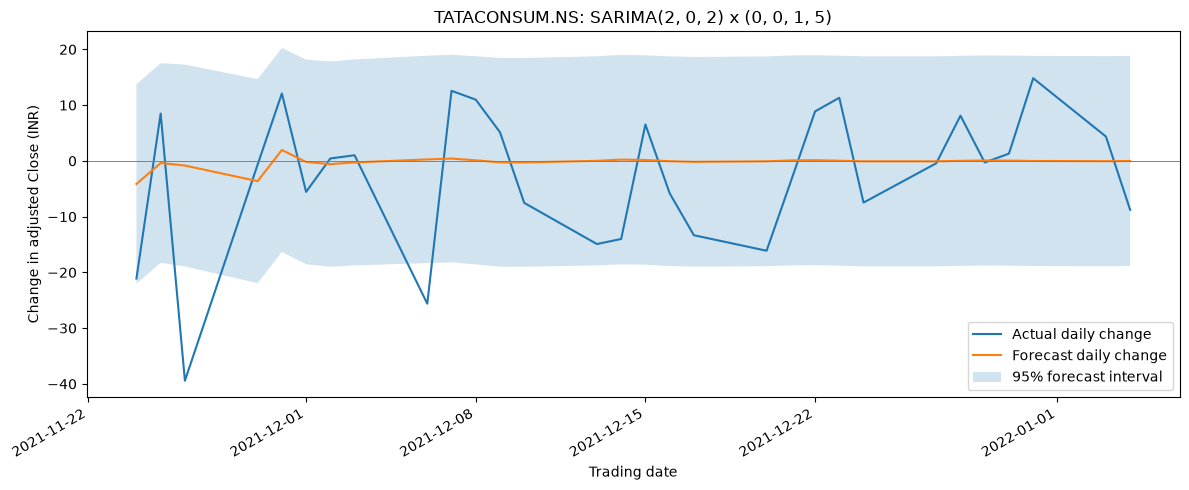

In [14]:
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(test.index, test, label="Actual daily change")
ax.plot(predictions.index, predictions, label="Forecast daily change")
ax.fill_between(test.index, intervals[:, 0], intervals[:, 1], alpha=0.2, label="95% forecast interval")
ax.axhline(0, color="grey", linewidth=0.7)
ax.set(title=f"TATACONSUM.NS: SARIMA{best_order} x {best_seasonal_order}",
       xlabel="Trading date", ylabel="Change in adjusted Close (INR)")
ax.legend()
fig.autofmt_xdate()
plt.tight_layout()
plt.show()